# Bottom-up labeling of mental operations at the chunk level

Single pass: the model labels each chunk of the corpus used in the main analyses, without knowing the taxonomy. Post hoc, the labels are compared with the top-down scores of the same chunks and with their position in time.

## Setup

In [5]:
# Resolve paths from the project root or any folder inside the project.
from pathlib import Path
import os

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "Deliberation.Rproj").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open this notebook from the project folder or Analyses/.")
os.chdir(project_root)

import pandas as pd
import numpy as np
import time
import os
import json
import re
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed
from openai import OpenAI

In [6]:
API_KEY = ""

client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=API_KEY,
)

MODEL = "deepseek/deepseek-v4-flash" 

temperature = 0
top_p = 1
max_tokens = 800  # headroom: reasoning tokens count against this ceiling
n = 1

WAIT_SECONDS = 60   # pause after a failed call, e.g. when we hit the rate limit
N_WORKERS = 10      # parallel requests

RERUN = False         # True ignores the saved labels and calls the llm again,
                    # the new results overwrite the old file
                    # False reuses whatever is already saved

In [7]:
def call_llm(prompt, token_ceiling=None, max_retries=4):
    # read the ceiling from the config at call time. taking it as a default
    # argument would freeze whatever value existed when the cell was executed
    token_ceiling = max_tokens if token_ceiling is None else token_ceiling
    # effort "none" is the only setting that reliably suppresses reasoning for this
    # model. "low" and "minimal" let the thinking tokens eat the whole budget and
    # the answer comes back empty
    for attempt in range(1, max_retries + 1):
        try:
            response = client.chat.completions.create(
                model=MODEL,
                messages=[{"role": "user", "content": prompt}],
                temperature=temperature,
                top_p=top_p,
                max_tokens=token_ceiling,
                n=n,
                extra_body={"reasoning": {"effort": "none", "exclude": True}},
                timeout=120,
            )
            d = response.model_dump()
            choice = (d.get('choices') or [{}])[0]
            usage = d.get('usage') or {}
            content = (choice.get('message') or {}).get('content')
            return {
                'content': content.strip() if content else None,
                'finish': choice.get('finish_reason'),
                'provider': d.get('provider'),
                'out_tok': usage.get('completion_tokens'),
                'reas_tok': (usage.get('completion_tokens_details') or {}).get('reasoning_tokens'),
                'error': None,
            }
        except Exception as e:
            err = f"{type(e).__name__}: {e}"
            print(f"call failed (attempt {attempt}/{max_retries}): {err}")
            if attempt < max_retries:
                time.sleep(WAIT_SECONDS)
    return {'content': None, 'finish': None, 'provider': None,
            'out_tok': None, 'reas_tok': None, 'error': err}

## Data

In [9]:
# same chunks as the main analyses, one row per chunk with its top-down scores
chunks = pd.read_csv('Output/scored_chunks.csv')
print(f"{len(chunks)} chunks from {chunks.groupby(['subject_id', 'question']).ngroups} trials")

# relative time of each chunk within its trial, as in the main analyses
g = chunks.groupby(['subject_id', 'question'])
chunks['trial_start'] = g['start_time'].transform('min')
chunks['trial_end'] = g['end_time'].transform('max')
chunks['norm_mid'] = ((chunks['start_time'] + chunks['end_time']) / 2 - chunks['trial_start']) / (chunks['trial_end'] - chunks['trial_start'])

out_dir = 'Output/Bottom_up'
os.makedirs(out_dir, exist_ok=True)

path_chunk_raw  = f'{out_dir}/chunk_pass1_labels_raw.csv'
path_chunk_long = f'{out_dir}/chunk_pass1_labels_long.csv'

4011 chunks from 969 trials


## Labeling the chunks

In [11]:
prompt_template = """
A participant is thinking aloud while solving the following reasoning problem:

QUESTION:
{question_text}

Here is one short passage from their verbalization:

PASSAGE:
{chunk_text}

Your task is to identify the primary reasoning operation the participant performs in
this passage: the main step they take in reasoning toward an answer to the problem.
These recordings come from participants deliberating aloud, so most identifiable
operations are steps in that deliberation.

Instructions:
- Give a single label, a singular noun of one or two words (e.g., "Calculation", not
  "Calculating").
- The label must name an operation the participant performs on the problem or on
  their own thinking.
  If your label would fit almost any sentence anyone could utter, it is too vague.
  Avoid labels that merely name a form of speech, such as Comment, Statement,
  Observation, Expression, Response, Reaction, Remark, or Description; give a more
  specific operation, or return None.
- Be as precise as the passage allows. A label that would fit any step of 
  deliberation carries no information: prefer one that distinguishes this passage
  from other passages in which the participant is also reasoning.
- Avoid overly generic labels that merely restate that the participant is thinking; name the particular operation instead. Where one noun would be
  too broad, use a two-word noun phrase that pins the operation down.
- Use "Repetition" whenever the passage is essentially nothing but the problem's own
  wording, or a close paraphrase of it. Use "Answer" when the passage is essentially nothing but the chosen
  answer.
  - Some passages are directed at the participant's own progress rather than at the
  problem. Name that operation too, and prefer it over "Repetition" when the passage
  announces a decision about reading rather than reproducing the problem's wording.
- Describe the operation performed by the participant, never
  what the problem is about.
- Do not evaluate the participant's reasoning normatively (e.g., as correct, incorrect, good,
  poor, biased). In particular, do not label an operation as mistaken (e.g.,
  "Misreading", "Misinterpretation"), but name the operation itself.
- For some passages, no operation is identifiable. For those
  the correct answer is None. A passage can be short and still carry an operation,
  especially when it concerns the participant's own progress.

Do not explain your choice. Return only the label on a single line, nothing else. If no operation is
identifiable, return only: None
"""

In [12]:
def label_chunk(row):
    prompt = prompt_template.format(
        question_text=row['question_text'],
        chunk_text=row['chunk_text'],
    )
    return call_llm(prompt)

In [13]:
key = ['subject_id', 'question', 'chunk_id']

# start from scratch or pick up where the last run stopped
if RERUN:
    print("rerun requested, the saved labels will be overwritten")
    done = set()
    results = []
elif os.path.exists(path_chunk_raw):
    existing = pd.read_csv(path_chunk_raw)
    # one row per chunk, keeping the labeled copy when there is one
    existing = (existing.sort_values('labels_extracted', na_position='last')
                        .drop_duplicates(key, keep='first'))
    # a call that came back without an error is finished, even when the answer was
    # empty: the model had nothing to label, which is an abstention rather than a
    # failure. only calls that actually errored are worth trying again
    if 'error' in existing.columns:
        completed = existing[existing['error'].isna()]
    else:
        completed = existing[existing['labels_extracted'].notna()]
    done = set(zip(completed['subject_id'], completed['question'], completed['chunk_id']))
    results = completed.to_dict(orient='records')
    n_abstain = int(completed['labels_extracted'].isna().sum())
    print(f"Resuming from previous run. {len(completed)} chunks completed "
          f"({n_abstain} of them abstentions), {len(existing) - len(completed)} to retry.")
else:
    done = set()
    results = []

n_empty = 0
todo = [row for _, row in chunks.iterrows()
        if (row['subject_id'], row['question'], row['chunk_id']) not in done]
print(f"{len(todo)} chunks left to label")

# parallel labeling, checkpoint every 100 completed chunks
# skipped entirely when all chunks are already in the saved file
if not todo:
    print("nothing to label, using the saved results")
if todo:
    with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
        futures = {pool.submit(label_chunk, row): row for row in todo}
        for i, fut in enumerate(tqdm(as_completed(futures), total=len(futures), desc="Labeling chunks", unit="chunk")):
            row = futures[fut]
            try:
                meta = fut.result()
            except Exception as e:
                print(f"error for chunk {row['subject_id']}-{row['question']}-{row['chunk_id']}: {e}")
                meta = {'content': None, 'error': f"{type(e).__name__}: {e}"}
            # an empty answer is a failure, not a result, so make it visible
            if meta.get('content') is None:
                n_empty += 1
                print(f"empty answer ({n_empty}) for "
                      f"{row['subject_id']}-{row['question']}-{row['chunk_id']}: "
                      f"finish={meta.get('finish')} out_tok={meta.get('out_tok')} "
                      f"reas_tok={meta.get('reas_tok')} provider={meta.get('provider')} "
                      f"error={meta.get('error')}", flush=True)
            results.append({
                'subject_id': row['subject_id'],
                'question': row['question'],
                'chunk_id': row['chunk_id'],
                'chunk_text': row['chunk_text'],
                'labels_extracted': meta.get('content'),
                'finish': meta.get('finish'),
                'provider': meta.get('provider'),
                'out_tok': meta.get('out_tok'),
                'reas_tok': meta.get('reas_tok'),
                'error': meta.get('error'),
            })
            if (i + 1) % 100 == 0:
                pd.DataFrame(results).to_csv(path_chunk_raw, index=False)

print(f"Final save... {n_empty} empty answers out of {len(todo)} calls")
pd.DataFrame(results).to_csv(path_chunk_raw, index=False)

Resuming from previous run. 4011 chunks completed (457 of them abstentions), 0 to retry.
0 chunks left to label
nothing to label, using the saved results
Final save... 0 empty answers out of 0 calls


## Parsing and normalization

In [15]:
def parse_label(text):
    if not isinstance(text, str):
        return None
    # the model occasionally explains itself before answering, and the label then
    # comes last, so read from the end and skip anything too long to be a label
    for line in reversed(text.split("\n")):
        line = line.strip().strip('`').strip('*').lstrip('#').strip()
        line = re.sub(r'^(label|answer)\s*:\s*', '', line, flags=re.I)
        line = line.strip().strip('"').strip("'").strip()
        # the word cap alone misses scripts without spaces, hence the character cap
        if not line or len(line.split()) > 4 or len(line) > 40:
            continue
        return None if line.lower() == 'none' else line
    return None

raw = pd.read_csv(path_chunk_raw)

rows = []
for _, r in tqdm(raw.iterrows(), total=len(raw), desc="Parsing"):
    label = parse_label(r['labels_extracted'])
    if label is not None:
        rows.append({
            'subject_id': r['subject_id'],
            'question': r['question'],
            'chunk_id': r['chunk_id'],
            'label_raw': label,
        })

labels_long = pd.DataFrame(rows)

# punctuation becomes a space so that hyphenated labels do not fuse
labels_long['label'] = (labels_long['label_raw']
                        .str.lower()
                        .str.replace(r'[^\w\s]', ' ', regex=True)
                        .str.replace(r'\s+', ' ', regex=True)
                        .str.strip()
                        .str.title())
labels_long = labels_long[labels_long['label'].str.len() > 0]
labels_long = labels_long[labels_long['label'] != 'None']

labels_long.to_csv(path_chunk_long, index=False)

print(f"{len(labels_long)} labeled chunks ({len(raw)} chunks processed)")
print(f"{labels_long['label'].nunique()} distinct labels")

Parsing: 100%|██████████| 4011/4011 [00:00<00:00, 48471.81it/s]

3552 labeled chunks (4011 chunks processed)
156 distinct labels


## First pass: label frequencies

In [17]:
label_counts = labels_long['label'].value_counts()
print(f"labels used only once: {(label_counts == 1).sum()}")
print(f"share of chunks without a label: {1 - len(labels_long) / len(raw):.1%}")


labels used only once: 81
share of chunks without a label: 11.4%


## First-pass plots

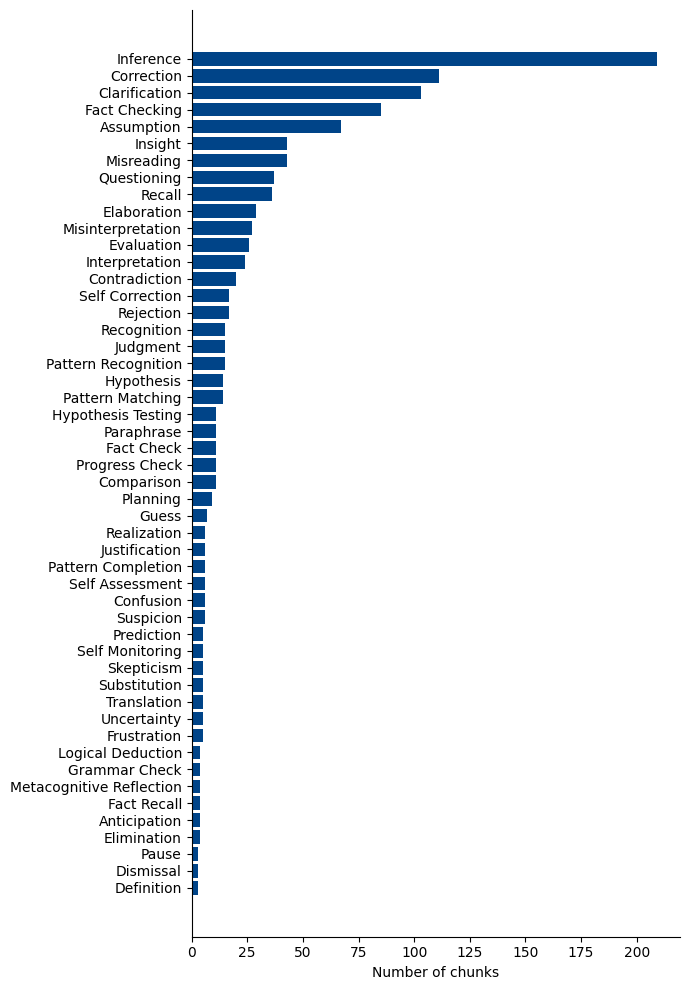

In [19]:
import matplotlib.pyplot as plt

label_counts = labels_long['label'].value_counts()

# the two verbal routines dwarf everything else, so leave them out of this plot only
routines = ['Repetition', 'Answer']
plot_counts = label_counts.drop(index=routines, errors='ignore')
top = plot_counts.head(50).iloc[::-1]

fig, ax = plt.subplots(figsize=(7, 10))
ax.barh(top.index, top.values, color='#004488')
ax.set_xlabel('Number of chunks')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(f'{out_dir}/chunk_labels_distribution.svg')
plt.show()

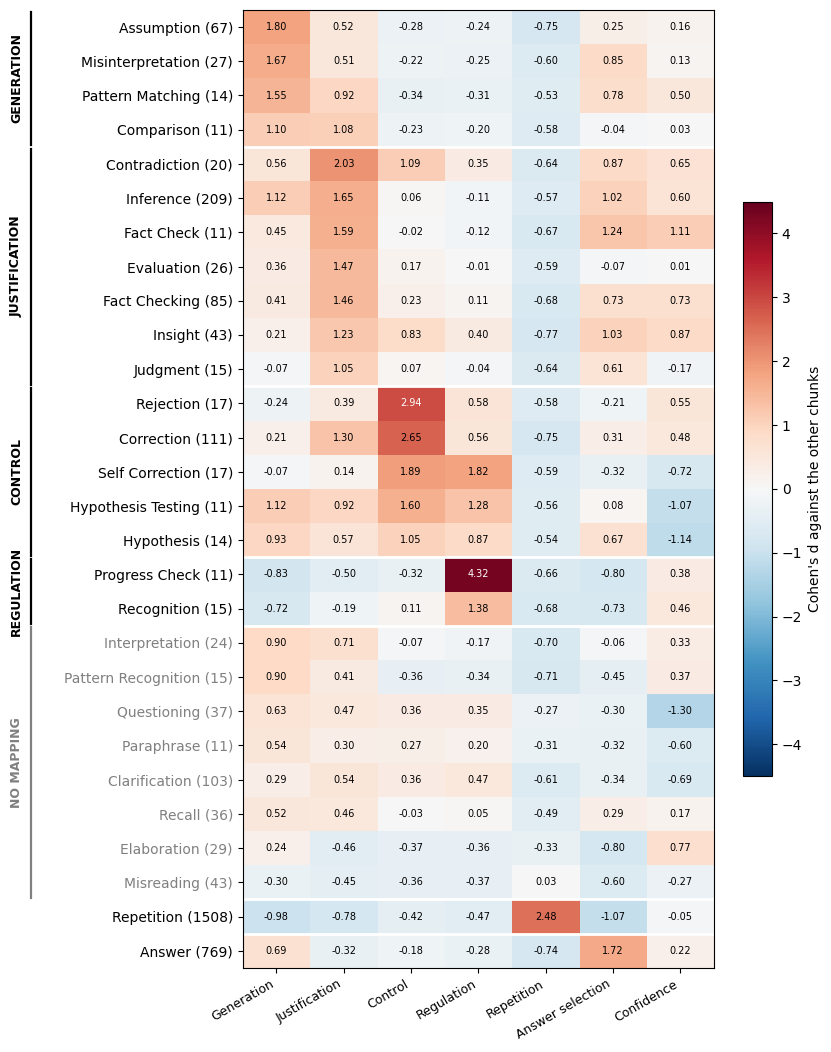

In [20]:
# convergence with the top-down scores: for each category, the standardized
# difference on every dimension between the chunks carrying it and all the others.
# cohen's d is used rather than a correlation because it does not shrink with the
# rarity of a category, so rows remain comparable
dims6 = {'generation_mean': 'Generation', 'justification_mean': 'Justification',
         'control_mean': 'Control', 'regulation_mean': 'Regulation',
         'repetition_mean': 'Repetition', 'answer_selection_mean': 'Answer selection'}
score_dims = {**dims6, 'confidence_mean': 'Confidence'}

# a category has to separate its best dimension by at least this much to be mapped
min_d = 1.0


def cohens_d_table(label_col, counts, min_n=10):
    scores = chunks.set_index(key)[list(score_dims)]
    rows = {}
    for lab in counts[counts >= min_n].index:
        members = set(map(tuple, labels_long.loc[labels_long[label_col] == lab, key].values))
        inside = scores.index.isin(members)
        a, b = scores[inside], scores[~inside]
        pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) /
                         (len(a) + len(b) - 2))
        rows[lab] = (a.mean() - b.mean()) / pooled
    out = pd.DataFrame(rows).T
    out.columns = list(score_dims.values())
    return out


def plot_cohens_d(d, counts, path, group_offset=-0.45):
    # a category joins the dimension it separates most, provided that separation
    # reaches min_d. confidence is shown as a column but never defines a group.
    # the two verbal routines are set apart at the bottom
    funcs = list(dims6.values())
    routine_cols = ['Repetition', 'Answer selection']
    best = d[funcs].max(axis=1)
    cluster = d[funcs].idxmax(axis=1).where(best >= min_d, 'No mapping')
    groups = [f for f in funcs if f not in routine_cols] + ['No mapping'] + routine_cols

    order = []
    for g in groups:
        members = d.index[cluster == g]
        strength = d.loc[members, g] if g in funcs else best[members]
        order += list(strength.sort_values(ascending=False).index)
    d, cluster = d.loc[order], cluster.loc[order]

    sizes = [(cluster == g).sum() for g in groups]
    starts = np.concatenate([[0], np.cumsum(sizes)])
    lim = np.ceil(np.abs(d.values).max() * 2) / 2
    d.round(2).to_csv(path.replace('.svg', '.csv'))

    fig, ax = plt.subplots(figsize=(7.6, 0.38 * len(d) + 1.8))
    im = ax.imshow(d.values, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
    ax.set_xticks(range(len(d.columns)), d.columns, rotation=30, ha='right', fontsize=9)
    ax.set_yticks(range(len(d)), [f"{l} ({counts[l]})" for l in d.index])
    for tick, lab in zip(ax.get_yticklabels(), d.index):
        if cluster[lab] == 'No mapping':
            tick.set_color('grey')
    for b in starts[1:-1]:
        ax.axhline(b - 0.5, color='white', linewidth=2)
    for i in range(d.shape[0]):
        for j in range(d.shape[1]):
            v = d.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha='center', va='center', fontsize=7,
                    color='white' if abs(v) > 0.6 * lim else 'black')

    # a bracket spanning the rows of each group, named on its left. the verbal
    # routines are left unbracketed, since they are not deliberation
    span = ax.get_yaxis_transform()
    for i, g in enumerate(groups):
        if not sizes[i] or g in routine_cols:
            continue
        y0, y1 = starts[i] - 0.45, starts[i + 1] - 0.55
        shade = 'grey' if g == 'No mapping' else 'black'
        ax.plot([group_offset, group_offset], [y0, y1], transform=span,
                color=shade, linewidth=1.6, clip_on=False)
        ax.text(group_offset - 0.03, (y0 + y1) / 2, g.upper(), transform=span,
                rotation=90, ha='center', va='center', fontsize=9,
                fontweight='bold', color=shade, clip_on=False)

    cb = fig.colorbar(im, shrink=0.6)
    cb.set_label("Cohen's d against the other chunks")
    plt.savefig(path, bbox_inches='tight')
    # raster and pdf copies for the manuscript, at print resolution
    plt.savefig(path.replace('.svg', '.png'), bbox_inches='tight', dpi=600)
    plt.savefig(path.replace('.svg', '.pdf'), bbox_inches='tight')
    plt.show()


plot_cohens_d(cohens_d_table('label', label_counts), label_counts,
              f'{out_dir}/chunk_labels_enrichment.svg')


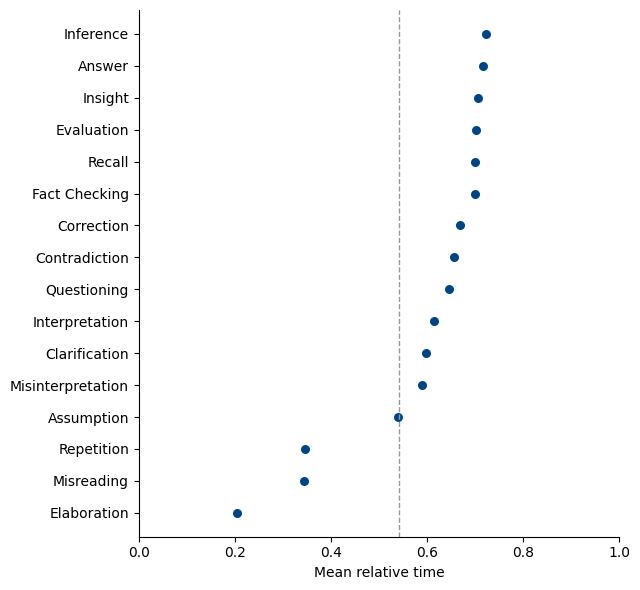

In [21]:
# where each frequent label sits in relative time
temporal = (labels_long.merge(chunks[key + ['norm_mid']], on=key)
            .groupby('label')['norm_mid']
            .agg(['mean', 'count']))
temporal = temporal[temporal['count'] >= 20].sort_values('mean')

fig, ax = plt.subplots(figsize=(6.5, 0.3 * len(temporal) + 1.2))
ax.scatter(temporal['mean'], range(len(temporal)), color='#004488', s=30)
ax.axvline(chunks['norm_mid'].mean(), color='#999999', ls='--', lw=1)
ax.set_yticks(range(len(temporal)), temporal.index)
ax.set_xlabel('Mean relative time')
ax.set_xlim(0, 1)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(f'{out_dir}/chunk_labels_temporal.svg')
plt.show()

## Second pass: merging the labels with the model

In [23]:
# the merging is done by the model in two stages: one call to design the category
# vocabulary, then many small parallel calls to assign labels to it. one single call
# for both jobs spends its whole token budget on reasoning and returns nothing.
# the inventory it sees is built from the chunk texts only, never from the scores
RUN_LLM_MERGE = False         # True calls the model, False reuses the saved files
path_categories = f'{out_dir}/pass2_llm_categories.json'
path_merge_map = f'{out_dir}/pass2_llm_merge_map.json'

texts = chunks[['subject_id', 'question', 'chunk_id', 'chunk_text']]
inv = labels_long.merge(texts, on=key)

STAGE_A_MIN_N = 3              # stage one designs the vocabulary from the labels that
                               # carry mass. rare labels are an assignment problem, not
                               # a design problem, and they cost stage one its budget

counts_first = labels_long['label'].value_counts()

def inventory_line(lab, n_ex):
    ex = (inv.loc[inv['label'] == lab, 'chunk_text']
            .dropna().astype(str).drop_duplicates().head(n_ex).tolist())
    return f"- {lab} (n={counts_first[lab]}): " + ' | '.join(e[:110] for e in ex)

# for stage two: every label, more evidence for the frequent ones
inv_lines = {lab: inventory_line(lab, 4 if n >= 10 else 2)
             for lab, n in counts_first.items()}

# for stage one: only the labels above the threshold, two excerpts each
inventory_a = "\n".join(inventory_line(lab, 2)
                        for lab, n in counts_first.items() if n >= STAGE_A_MIN_N)

print(f"{len(inv_lines)} labels in total, {len(''.join(inv_lines.values()).split())} words")
print(f"{sum(counts_first >= STAGE_A_MIN_N)} labels for stage one, "
      f"{len(inventory_a.split())} words "
      f"({counts_first[counts_first >= STAGE_A_MIN_N].sum() / len(labels_long):.0%} of labeled chunks)")

156 labels in total, 3869 words
58 labels for stage one, 1593 words (97% of labeled chunks)


In [24]:
# stage one: design the vocabulary. this is the part that needs deliberation, but the
# output is a short list, so there is little room for a truncated answer
STAGE_A_EFFORT = "low"
STAGE_A_MAX_TOKENS = 16000

vocab_prompt = f"""
Below is a list of labels that were assigned to short passages of people thinking
aloud while solving reasoning problems. Each line gives the label, how many passages
received it, and a few example passages.

Propose a set of broader categories that these labels could be grouped into, so that
each category is a recognisable operation with enough passages to analyse.

Rules:
- Group labels that name the same operation, including cases where one is a more
  specific version of the other, or a grammatical or spelling variant.
- Keep operations apart when they work differently, even if they sound related.
  Completing a sequence is not the same as noticing a regularity.
- Judge from the example passages, not from the label alone.
- Do not propose broad abstractions that would swallow most of the list. A category
  should still name something specific.
- Include "Repetition" and "Answer" unchanged. Reading the problem aloud, re-reading
  it and reciting it are all "Repetition": do not propose separate categories for them.
- Aim for roughly 20 to 35 categories.
- Each name should be a singular noun of one or two words. Reuse an existing label as
  the category name whenever one fits.
- This list leaves out labels that were used only once or twice. Those will have to be
  assigned to your categories afterwards, so leave room for related rare cases.

LABELS:
{inventory_a}

Return only the category names, one per line, with no numbering and no commentary.
"""

if RUN_LLM_MERGE or not os.path.exists(path_categories):
    # streamed on purpose. openrouter pads long non-streaming replies with keep-alive
    # lines that the client cannot parse as json, and streaming also lets us watch the
    # model think instead of staring at a blocked cell. reasoning is kept in the
    # stream only so that it can be counted, the text itself is discarded
    t0 = time.time()
    stream = client.chat.completions.create(
        model=MODEL, messages=[{"role": "user", "content": vocab_prompt}],
        temperature=0, max_tokens=STAGE_A_MAX_TOKENS, n=1,
        extra_body={"reasoning": {"effort": STAGE_A_EFFORT, "exclude": False}},
        stream=True, stream_options={"include_usage": True}, timeout=1200)

    parts, n_reasoning, finish, usage = [], 0, None, {}
    for chunk in stream:
        d = chunk.model_dump()
        usage = d.get('usage') or usage
        choice = (d.get('choices') or [{}])[0] if d.get('choices') else {}
        delta = choice.get('delta') or {}
        finish = choice.get('finish_reason') or finish
        if delta.get('reasoning'):
            n_reasoning += 1
            if n_reasoning % 100 == 0:
                print(f"  thinking, {n_reasoning} tokens, {time.time() - t0:.0f}s", flush=True)
        if delta.get('content'):
            parts.append(delta['content'])
            if len(parts) % 50 == 0:
                print(f"  writing, {len(parts)} tokens, {time.time() - t0:.0f}s", flush=True)
    reply = ''.join(parts)

    print(f"{time.time() - t0:.0f}s, finish={finish}, "
          f"out_tok={usage.get('completion_tokens')}, "
          f"reas_tok={(usage.get('completion_tokens_details') or {}).get('reasoning_tokens')}")
    if finish == 'length':
        raise RuntimeError("the reply hit the token ceiling before finishing the list. "
                           "raise STAGE_A_MIN_N to shrink the "
                           "input, or set STAGE_A_EFFORT to \'none\'")
    if not reply.strip():
        raise RuntimeError("stage one returned nothing. lower STAGE_A_EFFORT or raise "
                           "STAGE_A_MAX_TOKENS")
    categories = [l.strip().strip('-*`" ').strip() for l in reply.split("\n")]
    categories = [c for c in categories if c and len(c.split()) <= 3]
    with open(path_categories, 'w') as f:
        json.dump(categories, f, indent=1)
else:
    categories = json.load(open(path_categories))

print(f"{len(categories)} categories: {categories}")

29 categories: ['Answer', 'Assumption', 'Clarification', 'Comparison', 'Contradiction', 'Correction', 'Elaboration', 'Elimination', 'Evaluation', 'Fact Checking', 'Hypothesis', 'Inference', 'Insight', 'Misinterpretation', 'Paraphrase', 'Pattern Completion', 'Pattern Matching', 'Pattern Recognition', 'Planning', 'Prediction', 'Questioning', 'Recall', 'Recognition', 'Rejection', 'Repetition', 'Self Monitoring', 'Substitution', 'Transition', 'Uncertainty']


In [25]:
# stage two: assign every label to that fixed vocabulary. small batches, reasoning
# off, run in parallel. assigning to a given list is classification, not design
BATCH_SIZE = 20

# every label has to land on a listed category. leaving the model free to keep a
# label as its own category turned the rare tail into dozens of one-off categories
assign_vocab = categories + ['Other'] if 'Other' not in categories else categories

def assign_batch(batch):
    listing = "\n".join(inv_lines[lab] for lab in batch)
    prompt = f"""Here is a fixed list of categories:

{chr(10).join(assign_vocab)}

Assign each of the following labels to the category that best fits it, judging from
the example passages. You must choose a category from the list above, even when the
fit is loose. Use "Other" only when no category on the list is defensible.

LABELS:
{listing}

Return one line per label in the form
label => category
with no commentary."""
    meta = call_llm(prompt, token_ceiling=1500)
    return batch, (meta.get('content') or '')

todo_labels = list(inv_lines)
batches = [todo_labels[i:i + BATCH_SIZE] for i in range(0, len(todo_labels), BATCH_SIZE)]

if RUN_LLM_MERGE or not os.path.exists(path_merge_map):
    llm_merge, unparsed, invented = {}, [], []
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
        for batch, reply in tqdm(pool.map(assign_batch, batches), total=len(batches),
                                 desc="Assigning labels"):
            got = {}
            for line in reply.split("\n"):
                for sep in ('=>', '->', ':'):
                    if sep in line:
                        a, b = line.split(sep, 1)
                        a = a.strip().strip('-*`" ').strip()
                        b = b.strip().strip('-*`" ').strip()
                        if a and b:
                            got[a] = b
                        break
            for lab in batch:
                cat = got.get(lab)
                if cat is None:
                    unparsed.append(lab)
                elif cat in assign_vocab:
                    llm_merge[lab] = cat
                else:
                    # a category the model invented despite the instruction: keep it
                    # but count it, so drift stays visible rather than silent
                    llm_merge[lab] = cat
                    invented.append((lab, cat))
    print(f"{time.time() - t0:.0f}s for {len(batches)} batches")
    if unparsed:
        print(f"no assignment returned for {len(unparsed)} labels, left unchanged: {unparsed}")
    if invented:
        print(f"{len(invented)} labels put in categories outside the list: {invented[:20]}")
    with open(path_merge_map, 'w') as f:
        json.dump(llm_merge, f, indent=1)
else:
    llm_merge = json.load(open(path_merge_map))
    print(f"reusing the saved map, {len(llm_merge)} labels")

# categories the model invented rather than taking from the list
off_list = sorted({v for v in llm_merge.values()} - set(assign_vocab))
if off_list:
    print(f"categories not in the stage one list ({len(off_list)}): {off_list}")
n_other = int((labels_long['label'].map(lambda l: llm_merge.get(l, l)) == 'Other').sum())
print(f"{n_other} chunks ({n_other / len(labels_long):.1%}) landed in Other")

labels_long['label_pass2'] = labels_long['label'].map(lambda l: llm_merge.get(l, l))
labels_long.to_csv(path_chunk_long, index=False)
print(f"{labels_long['label'].nunique()} labels mapped onto "
      f"{labels_long['label_pass2'].nunique()} categories")

reusing the saved map, 156 labels
categories not in the stage one list (6): ['Agreement Check', 'Emotional Reaction', 'Imagination', 'Segmentation', 'Visualization', 'Wordplay']
17 chunks (0.5%) landed in Other
156 labels mapped onto 36 categories


## Second-pass plots

156 labels in the first pass, 36 after the merge
categories with n >= 10: 26 (covering 99% of labeled chunks)


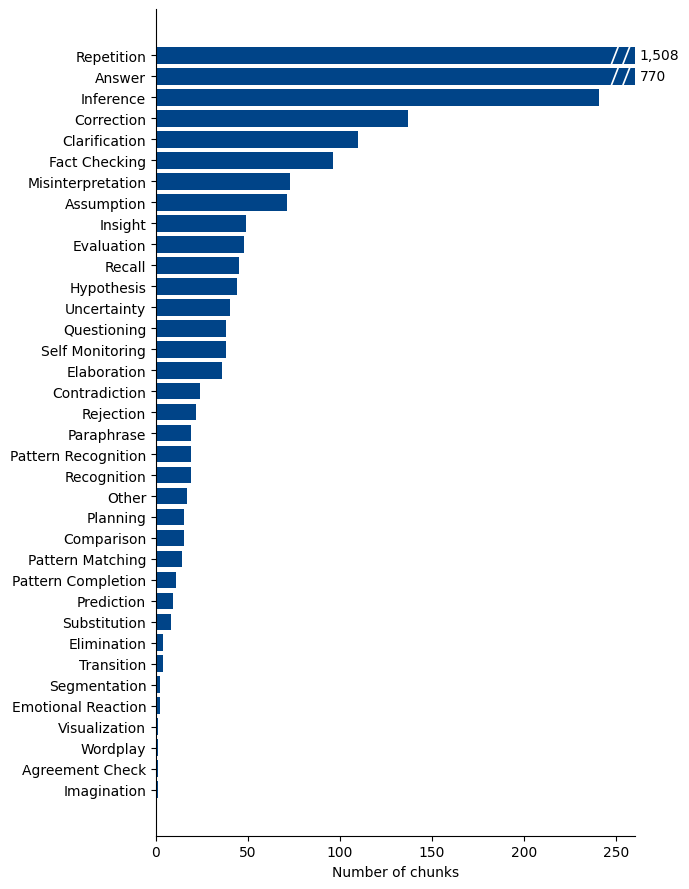

In [70]:
counts_pass2 = labels_long['label_pass2'].value_counts()
print(f"{labels_long['label'].nunique()} labels in the first pass, "
      f"{labels_long['label_pass2'].nunique()} after the merge")
print(f"categories with n >= 10: {(counts_pass2 >= 10).sum()} "
      f"(covering {counts_pass2[counts_pass2 >= 10].sum() / len(labels_long):.0%} of labeled chunks)")

top = counts_pass2.iloc[::-1]

# the routines are an order of magnitude above the rest, so the axis stops just past
# the largest other category. the bars that run off are marked with a break and
# their true count is written beside them
cap = counts_pass2.drop(index=routines, errors='ignore').max() * 1.08

fig, ax = plt.subplots(figsize=(7, max(4, 0.25 * len(top))))
ax.barh(top.index, top.values, color='#004488')
ax.set_xlim(0, cap)
ax.set_xlabel('Number of chunks')

dx = cap * 0.012          # half-width of the break marks
for y, (lab, v) in enumerate(top.items()):
    if v > cap:
        xb = cap * 0.97
        for off in (-dx, dx):
            ax.plot([xb + off - dx * 0.6, xb + off + dx * 0.6], [y - 0.42, y + 0.42],
                    color='white', lw=1.2, solid_capstyle='butt', zorder=3,
                    clip_on=False)
        ax.text(cap * 1.01, y, f'{v:,}', va='center', ha='left',
                fontsize=10, color='black', clip_on=False)

ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(f'{out_dir}/chunk_labels_distribution_pass2.svg')
plt.show()

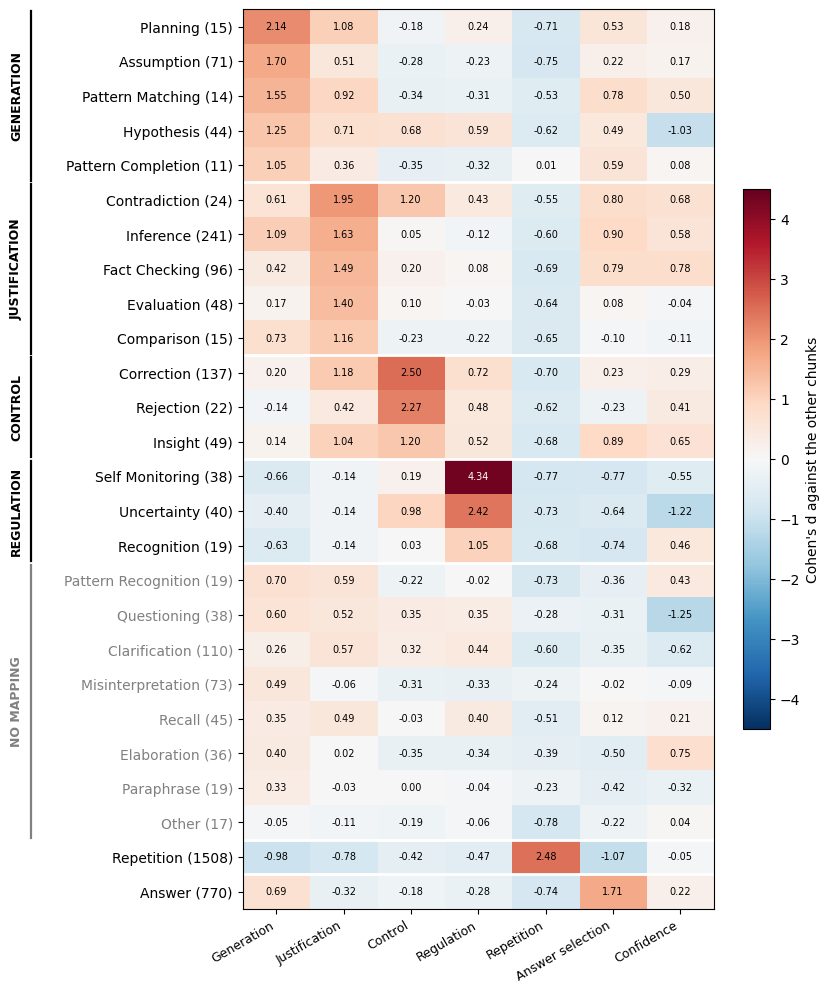

In [28]:
plot_cohens_d(cohens_d_table('label_pass2', counts_pass2), counts_pass2,
              f'{out_dir}/chunk_labels_enrichment_pass2.svg')


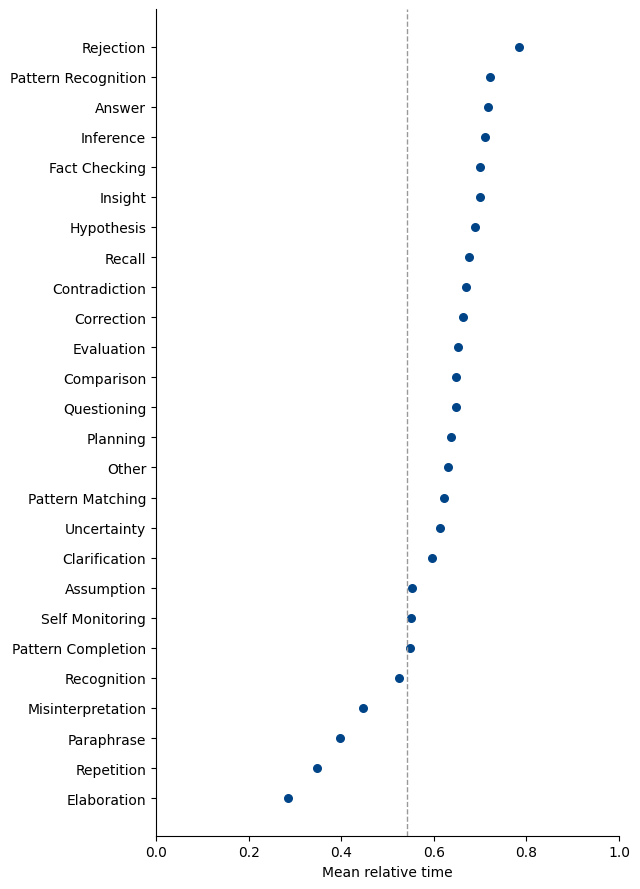

In [29]:
# where each merged category sits in relative time
temporal2 = (labels_long.merge(chunks[key + ['norm_mid']], on=key)
             .groupby('label_pass2')['norm_mid']
             .agg(['mean', 'count']))
temporal2 = temporal2[temporal2['count'] >= 10].sort_values('mean')

fig, ax = plt.subplots(figsize=(6.5, 0.3 * len(temporal2) + 1.2))
ax.scatter(temporal2['mean'], range(len(temporal2)), color='#004488', s=30)
ax.axvline(chunks['norm_mid'].mean(), color='#999999', ls='--', lw=1)
ax.set_yticks(range(len(temporal2)), temporal2.index)
ax.set_xlabel('Mean relative time')
ax.set_xlim(0, 1)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(f'{out_dir}/chunk_labels_temporal_pass2.svg')
plt.show()